# Phase 2.1: PubMed Query Plan

Generate the inspectable PubMed query plan from Phase 1 species mappings and the tracked query templates.


In [1]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pathogen_atlas_v2").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from pathogen_atlas_v2 import notebook_utils as nbutils


In [2]:
NOTEBOOK_CONFIG_PATH = "configs/notebook_parameters.yaml"
PARAMS = nbutils.notebook_phase_parameters("phase2_query_plan", NOTEBOOK_CONFIG_PATH)

TEMPLATE_CONFIG_PATH = PARAMS["template_config_path"]
FILTER_CONFIG_PATH = PARAMS["filter_config_path"]
PREVIEW_ROWS = int(PARAMS["preview_rows"])

In [3]:
query_plan_result = nbutils.materialize_phase_2_query_plan(TEMPLATE_CONFIG_PATH, FILTER_CONFIG_PATH)
query_plan_summary = nbutils.query_plan_result_summary(query_plan_result)
display(query_plan_summary["overview"])


,field,value
0,status,generated
1,reason,None
2,query_plan_path,/Users/f.costa/Documents/Projects/Repositories...
3,query_plan_approval,draft
4,query_count,68397


## Query Template

Tracked template before placeholder rendering.


In [4]:
print(nbutils.wrap_text(nbutils.phase2_query_template_text(TEMPLATE_CONFIG_PATH), width=100))


({matched_names}) AND ({human_terms}) AND ({infection_terms}) AND ("{min_year}"[Date - Publication]
: "{max_year}"[Date - Publication])


## Concrete Query Example

One fully rendered query from the generated query plan.


In [5]:
display(nbutils.phase2_concrete_query_example_metadata(query_plan_result["path"], prefer_synonyms=True))


,status,canonical_species,synonym_count,field,template_id,matched_names
0,from_compact_query_plan,Streptomyces hiroshimensis,15,Title/Abstract,exact_species_human_infection_context,"Streptomyces aureoversilis, Streptomyces biver..."


In [6]:
print(nbutils.wrap_text(nbutils.phase2_concrete_query_example_text(query_plan_result["path"], prefer_synonyms=True), width=100))


("Streptomyces aureoversilis"[Title/Abstract] OR "Streptomyces biverticillatus"[Title/Abstract] OR
"Streptomyces fervens"[Title/Abstract] OR "Streptomyces hiroshimensis"[Title/Abstract] OR
"Streptomyces rectiverticillatus"[Title/Abstract] OR "Streptomyces
roseoverticillatus"[Title/Abstract] OR "Streptomyces salmonis"[Title/Abstract] OR "Streptomyces
spitsbergensis"[Title/Abstract] OR "Streptoverticillium aureoversile"[Title/Abstract] OR
"Streptoverticillium biverticillatum"[Title/Abstract] OR "Streptoverticillium
fervens"[Title/Abstract] OR "Streptoverticillium hiroshimense"[Title/Abstract] OR
"Streptoverticillium rectiverticillatum"[Title/Abstract] OR "Streptoverticillium
roseoverticillatum"[Title/Abstract] OR "Streptoverticillium salmonis"[Title/Abstract]) AND
("case"[Title/Abstract] OR "cases"[Title/Abstract] OR "clinical"[Title/Abstract] OR
"clinically"[Title/Abstract] OR "human"[Title/Abstract] OR "humans"[Title/Abstract] OR
"male"[Title/Abstract] OR "males"[Title/Abstract] OR "ne

In [7]:
display(nbutils.phase2_query_plan_preview(query_plan_result["path"], n_rows=PREVIEW_ROWS))


,query_id,canonical_species,synonym_count,matched_names,field,template_id,query
0,q_e5c37e79434664f5,Abditibacterium utsteinense,1,Abditibacterium utsteinense,Title/Abstract,exact_species_human_infection_context,"(""Abditibacterium utsteinense""[Title/Abstract]..."
1,q_6eb4fb97110ee7f1,Abditibacterium utsteinense,1,Abditibacterium utsteinense,Keywords,exact_species_human_infection_context,"(""Abditibacterium utsteinense""[Keywords]) AND ..."
2,q_e7c59e17318610d6,Abditibacterium utsteinense,1,Abditibacterium utsteinense,MeSH Terms,exact_species_human_infection_context,"(""Abditibacterium utsteinense""[MeSH Terms]) AN..."
3,q_a32a3ab4c29eb90a,Abiotrophia defectiva,2,"Abiotrophia defectiva, Streptococcus defectivus",Title/Abstract,exact_species_human_infection_context,"(""Abiotrophia defectiva""[Title/Abstract] OR ""S..."
4,q_6095bb8545bc8f11,Abiotrophia defectiva,2,"Abiotrophia defectiva, Streptococcus defectivus",Keywords,exact_species_human_infection_context,"(""Abiotrophia defectiva""[Keywords] OR ""Strepto..."
5,q_98f32d4da2b12807,Abiotrophia defectiva,2,"Abiotrophia defectiva, Streptococcus defectivus",MeSH Terms,exact_species_human_infection_context,"(""Abiotrophia defectiva""[MeSH Terms] OR ""Strep..."
6,q_467e5ced5c065be2,Absicoccus intestinalis,1,Absicoccus intestinalis,Title/Abstract,exact_species_human_infection_context,"(""Absicoccus intestinalis""[Title/Abstract]) AN..."
7,q_ab9dd83f995d3e17,Absicoccus intestinalis,1,Absicoccus intestinalis,Keywords,exact_species_human_infection_context,"(""Absicoccus intestinalis""[Keywords]) AND (""ca..."
8,q_43c5be3c6648a4b7,Absicoccus intestinalis,1,Absicoccus intestinalis,MeSH Terms,exact_species_human_infection_context,"(""Absicoccus intestinalis""[MeSH Terms]) AND (""..."
9,q_df803a63d482233c,Absicoccus porci,1,Absicoccus porci,Title/Abstract,exact_species_human_infection_context,"(""Absicoccus porci""[Title/Abstract]) AND (""cas..."


In [8]:
phase2_paths = nbutils.phase2_output_paths(TEMPLATE_CONFIG_PATH)
display(nbutils.existing_outputs(phase2_paths))


,name,path,exists,rows,size_bytes,content_type
0,query_plan,/Users/f.costa/Documents/Projects/Repositories...,True,NaN,3565342,yaml
1,raw_search_results_path,/Users/f.costa/Documents/Projects/Repositories...,True,68397.0,35815970,jsonl
2,canonical_pmid_index_path,/Users/f.costa/Documents/Projects/Repositories...,True,22799.0,11210668,parquet
3,sampled_canonical_pmid_index_path,/Users/f.costa/Documents/Projects/Repositories...,True,22799.0,3109696,parquet
4,raw_article_records_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,jsonl
5,filtered_species_matches_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,parquet
6,filtered_filter_matches_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,parquet
7,release_abstracts_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,parquet
8,release_species_matches_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,parquet
9,release_filter_matches_path,/Users/f.costa/Documents/Projects/Repositories...,False,NaN,0,parquet


## Synonym Distribution

Summary of the number of synonyms per canonical species in the generated query plan.


In [9]:
display(nbutils.phase2_synonym_distribution_summary(query_plan_result["path"]))


,canonical_species,species_with_synonyms,species_without_synonyms,mean_synonyms,median_synonyms,max_synonyms
0,22799,4841,17958,0.260318,0.0,14


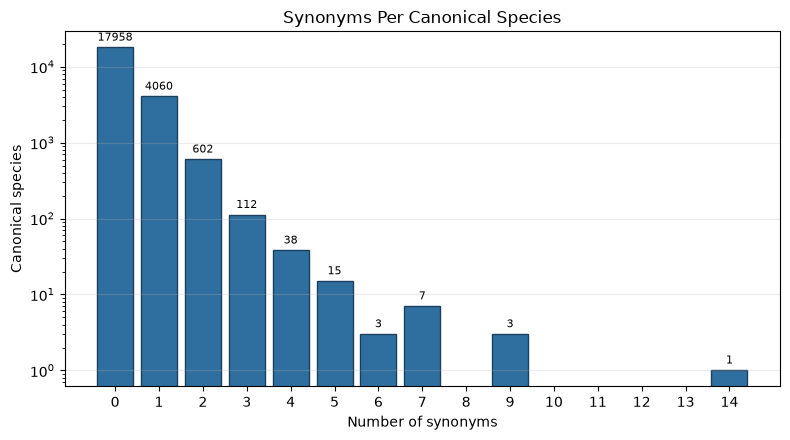

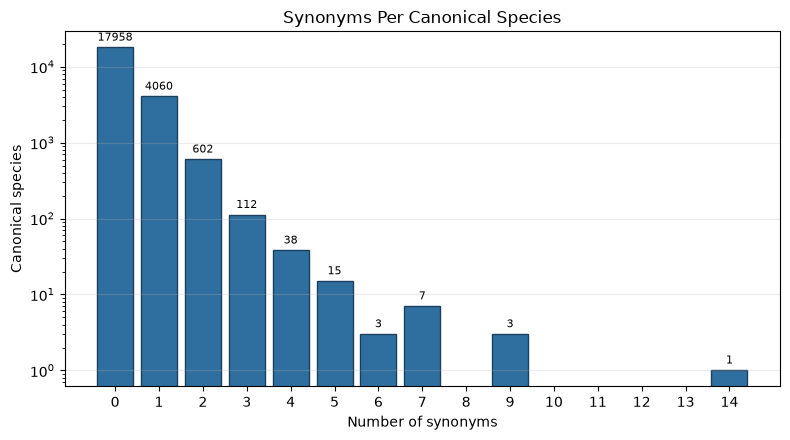

In [10]:
_ = display(nbutils.plot_phase2_synonym_distribution(query_plan_result["path"]))
